##Notebook 3: Research Question 2: Do the channels with the highest conversion rates also produce sellets who generate revenue or is there a gap between converting and selling?

Inputs: Lead_Population_90d.csv, olist_closed_deals_dataset.csv, olist_order_items_dataset.csv

Approach:
1. Link converted leads to their sales
2. Count how many acquired sellers actually sold somethin
3. Show the revenue generated per seller
4. Compare conversion and revenue by channel

Output: Display a table showing the revenue, and channel comparison table

In [1]:
#Loading the Lead_Population_90d file from notebook 01, plus deals and order items file for revenue
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/Lead_Population_90d.csv')
DLS = pd.read_csv('/content/olist_closed_deals_dataset.csv')
ITM = pd.read_csv('/content/olist_order_items_dataset.csv')

df['origin'] = df['origin'].fillna('missing')

print('leads:', df.shape)
print('deals:', DLS.shape)
print('order items:', ITM.shape)

leads: (6198, 9)
deals: (842, 14)
order items: (112650, 7)


In [2]:
#Now we only keep the leads that became sellers. We join the tables using mql_id and seller_id
#Then we look at the toal sales per seller by adding up the price of all the items that each seller sold
#Then we do another join this time using the seller_i to to understand the revenue for each seller

conv = df[df['converted_ever'] == 1]
sellers = conv.merge(DLS[['mql_id', 'seller_id']], on='mql_id', how='left')

revenue = ITM.groupby('seller_id').agg(revenue=('price', 'sum')).reset_index()

sellers = sellers.merge(revenue, on='seller_id', how='left')
sellers['revenue'] = sellers['revenue'].fillna(0)

print('acquired sellers:', len(sellers))
print(sellers[['mql_id', 'origin', 'seller_id', 'revenue']].head())

acquired sellers: 792
                             mql_id          origin  \
0  5420aad7fec3549a85876ba1c529bd84  organic_search   
1  a555fb36b9368110ede0f043dfc3b9a0        referral   
2  327174d3648a2d047e8940d7d15204ca  organic_search   
3  f5fee8f7da74f4887f5bcae2bafb6dd6     paid_search   
4  b94fba7670eeb44dce2a0d8eb790e9f5  organic_search   

                          seller_id   revenue  
0  2c43fb513632d29b3b58df74816f1b06    858.00  
1  bbb7d7893a450660432ea6652310ebb7      0.00  
2  612170e34b97004b3ba37eae81836b4c  23065.02  
3  21e1781e36faf92725dde4730a88ca0f      0.00  
4  1c742ac33582852aaf3bcfbf5893abcf     97.90  


In [3]:
#We now can check if each acquired seller made at least 1 sale or not

sold = (sellers['revenue'] > 0).sum()
print('sellers who sold:', sold, 'of', len(sellers))
print('percentage of sellers who sold at least one item:', round(100 * sold / len(sellers), 1),'%')

sellers who sold: 366 of 792
percentage of sellers who sold at least one item: 46.2 %


mean revenue: 1812.59
median revenue: 545.86
max revenue: 113628.97
top 10% of sellers bring in: 64.7 % of revenue


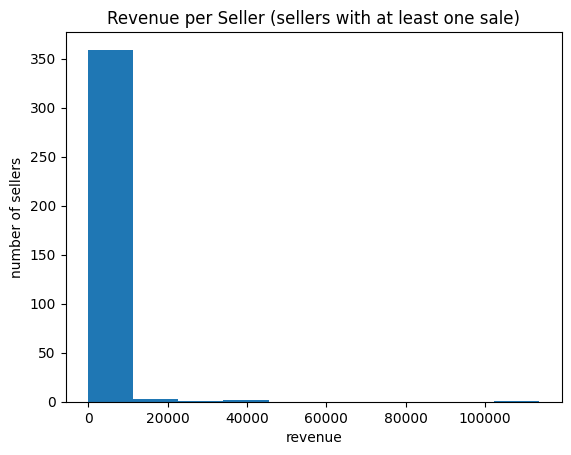

In [4]:
#Now we can look at the sellers who made at least one sale or more and look at the mean, median, and mode of this subsect of sellers.
#Then we look at the top 10% of sellers who made the most revenue(these are obviously selles who made well over one sale).
#Finaly we can see a histogram of the revenue per seller of the sellers who made one sale or more.

sold_sellers = sellers[sellers['revenue'] > 0]

print('mean revenue:', round(sold_sellers['revenue'].mean(), 2))
print('median revenue:', round(sold_sellers['revenue'].median(), 2))
print('max revenue:', round(sold_sellers['revenue'].max(), 2))

top_10_percent_sellers = int(len(sold_sellers) * 0.10)
top_revenue = sold_sellers['revenue'].sort_values(ascending=False).head(top_10_percent_sellers).sum()
print('top 10% of sellers bring in:', round(100 * top_revenue / sold_sellers['revenue'].sum(), 1),'% of revenue')

sold_sellers['revenue'].plot(kind='hist')
plt.title('Revenue per Seller (sellers with at least one sale)')
plt.xlabel('revenue')
plt.ylabel('number of sellers')
plt.show()

In [5]:
#We look at the conversion rate per channel in the lead population 90 day file.
#Then we look at the share of the channel sellers who made at least one sale
#Then we look at the median revenue of the channel sellers that made at leas one sale
#Lastly I turned this into a results table to better understand the differences between the conversions and the sellers who sold something.

conv_by_origin = df.groupby('origin').agg(leads=('mql_id', 'size'),
                                          conv_rate=('converted', 'mean')).reset_index()
conv_by_origin['conv_rate'] = (100 * conv_by_origin['conv_rate']).round(1)

sellers['sold'] = (sellers['revenue'] > 0).astype(int)
sold_by_origin = sellers.groupby('origin').agg(sellers=('seller_id', 'size'),
                                               sold_pct=('sold', 'mean')).reset_index()
sold_by_origin['sold_pct'] = (100 * sold_by_origin['sold_pct']).round(1)

rev_by_origin = sold_sellers.groupby('origin').agg(median_revenue=('revenue', 'median')).reset_index()
rev_by_origin['median_revenue'] = rev_by_origin['median_revenue'].round(0)

channel_table = conv_by_origin.merge(sold_by_origin, on='origin', how='left')
channel_table = channel_table.merge(rev_by_origin, on='origin', how='left')
channel_table = channel_table.sort_values('conv_rate', ascending=False)
print(channel_table)

               origin  leads  conv_rate  sellers  sold_pct  median_revenue
3             missing     51       23.5       13      30.8           314.0
10            unknown    838       18.7      170      45.9           673.0
0      direct_traffic    390       12.8       56      55.4           399.0
7         paid_search   1217       12.2      177      52.0           500.0
4      organic_search   1796       12.0      259      43.6           634.0
8            referral    220        9.5       24      37.5          1368.0
1             display     80        7.5        6      33.3           462.0
6   other_publicities     42        7.1        3       0.0             NaN
9              social   1090        5.0       66      43.9           722.0
5               other    115        3.5        4      50.0          3444.0
2               email    359        3.3       14      42.9           338.0
